# Correlation between affinity and binding scores for c259 TCR binding peptide mutants

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pingouin as pg
import seaborn as sns
from scipy.stats import pearsonr

In [2]:
AFFINITY_CUTOFF = 100  # uM

In [3]:
sequences = pd.read_csv('../data/interim/sequences_c259_mutational_scan_affinity.csv', index_col='id')

In [4]:
sequences.loc[sequences['geometric_mean'] > AFFINITY_CUTOFF, 'geometric_mean'] = np.inf
sequences['geometric_mean'] = sequences['geometric_mean'].fillna(np.inf)
sequences['affinity_norm'] = sequences['geometric_mean'].min() / sequences['geometric_mean']

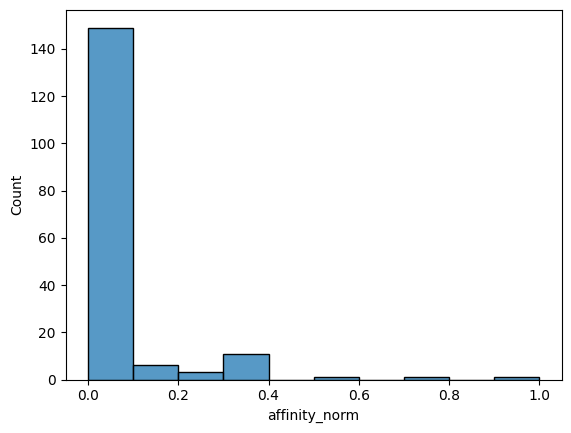

In [5]:
sns.histplot(sequences, x='affinity_norm', bins=10)
plt.show()

In [6]:
binding_scores = pd.read_csv(
    '../data/processed/af3_af3_tcrmodel2_c259_mutational_scan_affinity_pae_aggregator_predictions.csv'
)
binding_scores['prediction'] = binding_scores[
    ['prediction_1', 'prediction_2', 'prediction_3', 'prediction_4', 'prediction_5']
].apply('median', axis=1)

binding_scores = binding_scores.merge(sequences, how='inner', left_on='name', right_index=True)

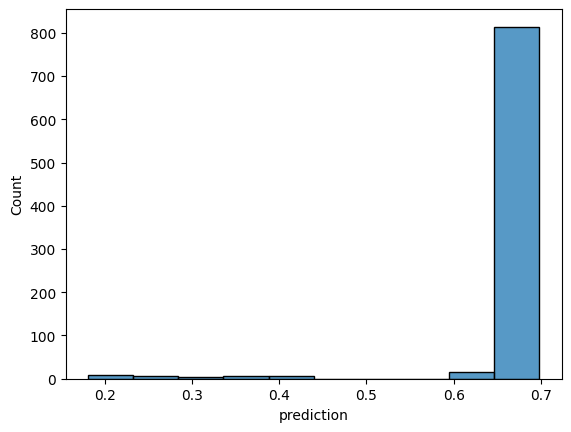

In [7]:
sns.histplot(binding_scores, x='prediction', bins=10)
plt.show()

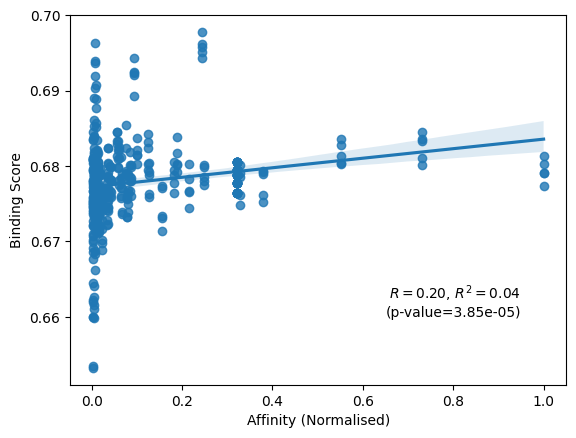

In [8]:
ax = sns.regplot(binding_scores[~np.isinf(binding_scores['geometric_mean'])], x='affinity_norm', y='prediction')

r, p_val = pearsonr(
    binding_scores.loc[~np.isinf(binding_scores['geometric_mean']), 'affinity_norm'],
    binding_scores.loc[~np.isinf(binding_scores['geometric_mean']), 'prediction'],
    alternative='greater',
)
ax.text(0.95, 0.66, f'$R={r:.2f}$, $R^2={r**2:.2f}$\n(p-value={p_val:.2e})', ha='right')

ax.set_ylabel('Binding Score')
ax.set_xlabel('Affinity (Normalised)')

plt.savefig('../report/figures/c259_binding_score_affinity_regression.svg')
plt.show()

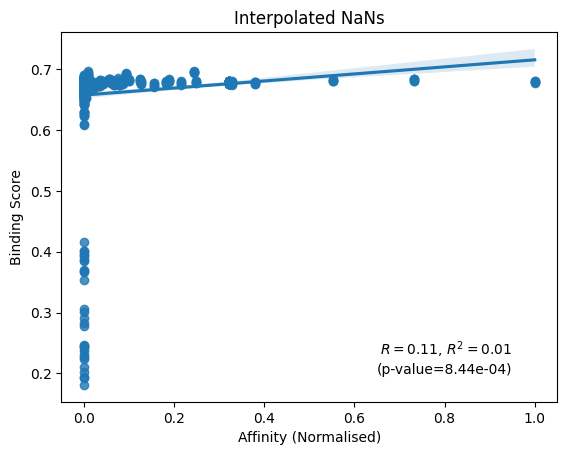

In [9]:
ax = sns.regplot(binding_scores, x='affinity_norm', y='prediction')

r, p_val = pearsonr(binding_scores['affinity_norm'], binding_scores['prediction'], alternative='greater')
ax.text(0.95, 0.2, f'$R={r:.2f}$, $R^2={r**2:.2f}$\n(p-value={p_val:.2e})', ha='right')

ax.set_ylabel('Binding Score')
ax.set_xlabel('Affinity (Normalised)')
ax.set_title('Interpolated NaNs')

plt.show()

In [10]:
binding_scores['status'] = 'Binder'
binding_scores.loc[np.isinf(binding_scores['geometric_mean']), 'status'] = 'Non-Binder'

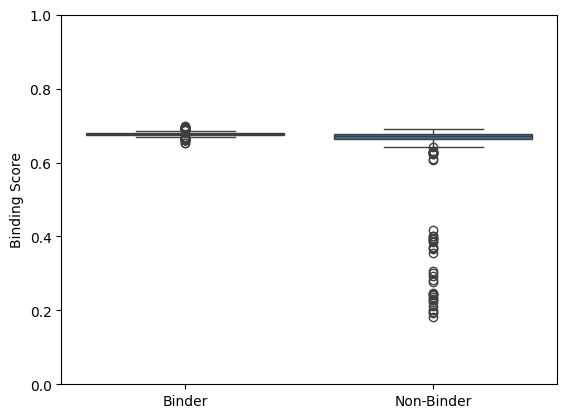

In [11]:
ax = sns.boxplot(binding_scores, y='prediction', x='status')

ax.set_ylim(0, 1)

ax.set_xlabel('')
ax.set_ylabel('Binding Score')

plt.savefig('../report/figures/tcr_c259_affinity_disruption_boxplot.svg')
plt.show()

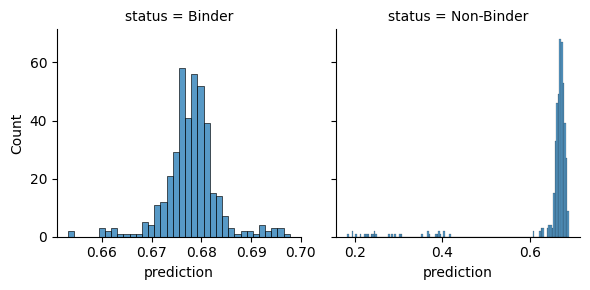

In [12]:
grid = sns.FacetGrid(binding_scores, col='status', sharex=False)
grid.map_dataframe(sns.histplot, x='prediction')

plt.show()

In [13]:
pg.ttest(
    binding_scores.query("status == 'Binder'")['prediction'],
    binding_scores.query("status == 'Non-Binder'")['prediction'],
    alternative='greater',
)

,T,dof,alternative,p-val,CI95%,cohen-d,BF10,power
T-test,7.399369,462.724862,greater,3.248038e-13,"[0.03, inf]",0.471919,3.533e+10,1.0
